In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [4]:
# Check blank values in TotalCharges
print("Blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())

# Convert TotalCharges from text to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges after conversion:", df["TotalCharges"].isnull().sum())

Blank TotalCharges: 11
Missing TotalCharges after conversion: 11


In [5]:
# Inspect rows with missing TotalCharges
df[df["TotalCharges"].isnull()][
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [6]:
# Check the tenure of those customers
print(df.loc[df["TotalCharges"].isnull(), "tenure"].value_counts())

tenure
0    11
Name: count, dtype: int64


In [7]:
# Fill missing TotalCharges with 0 for zero-tenure customers
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify the cleaning
print("Missing values remaining:", df["TotalCharges"].isnull().sum())
print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Dataset shape:", df.shape)

Missing values remaining: 0
TotalCharges data type: float64
Dataset shape: (7043, 21)


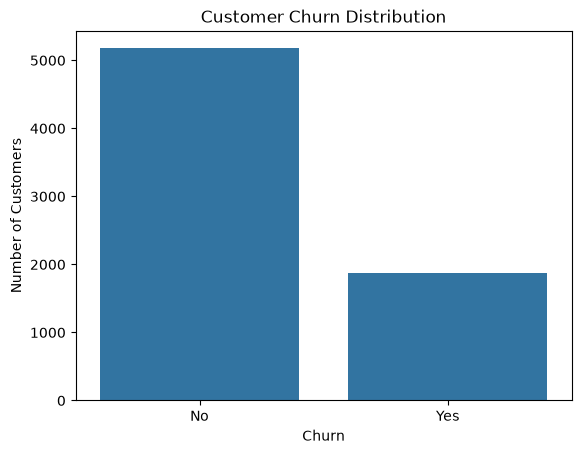

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

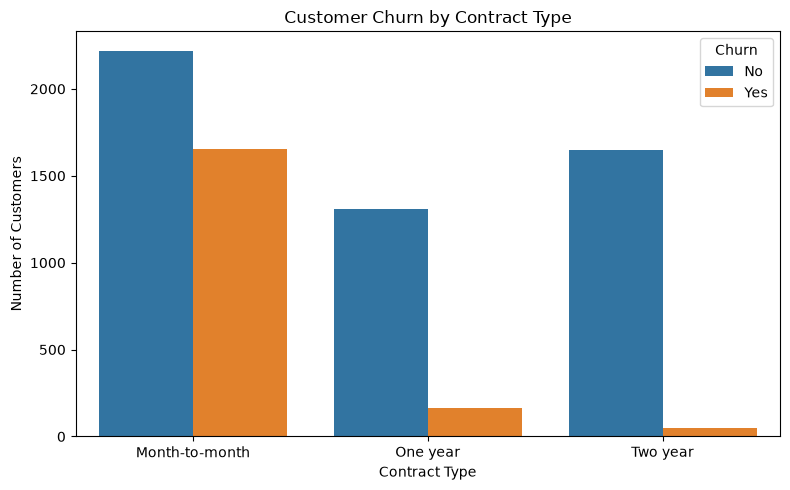

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [10]:
churn_rate = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn rate by contract type:")
print(churn_rate.round(2))

Churn rate by contract type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


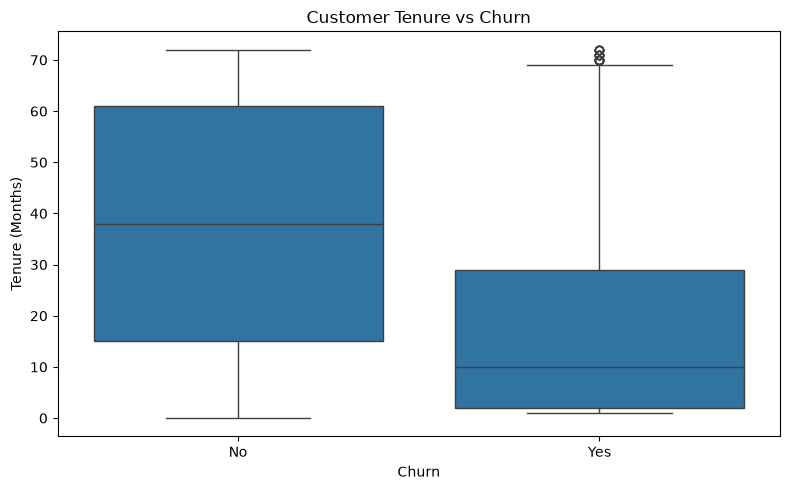

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [12]:
print(df.groupby("Churn")["tenure"].describe().round(2))

        count   mean    std  min   25%   50%   75%   max
Churn                                                   
No     5174.0  37.57  24.11  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.98  19.53  1.0   2.0  10.0  29.0  72.0


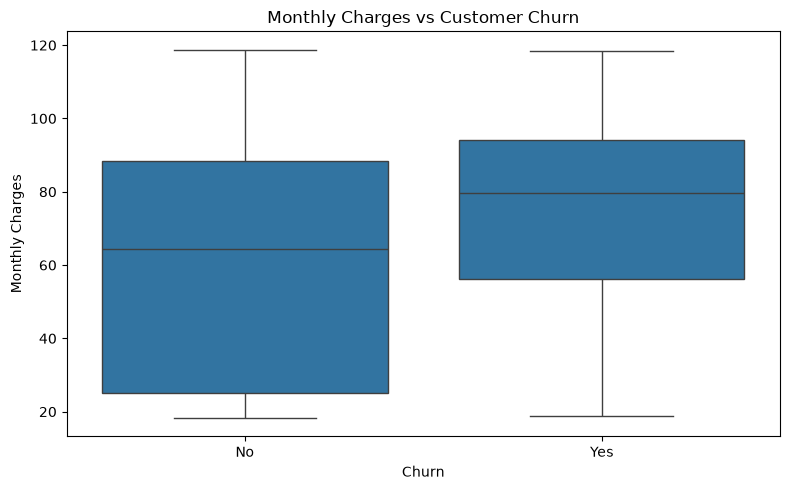

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [14]:
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [15]:
# Remove customerID because it is only an identifier
df_model = df.drop(columns=["customerID"]).copy()

# Convert the target into numeric values
df_model["Churn"] = df_model["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Separate input features and target
X = df_model.drop(columns=["Churn"])
y = df_model["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5634
Testing samples: 1409


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1-Score: 0.604
ROC-AUC: 0.8421

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



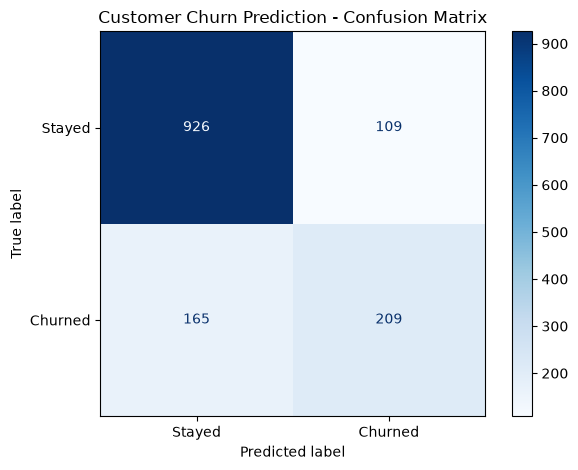

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"]
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Customer Churn Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from sklearn.pipeline import Pipeline
import pandas as pd

algorithms = {
    "Logistic Regression": model,
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", ExtraTreesClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []

for name, algorithm in algorithms.items():
    algorithm.fit(X_train, y_train)

    predictions = algorithm.predict(X_test)
    probabilities = algorithm.predict_proba(X_test)[:, 1]

    results.append({
        "Algorithm": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Precision": round(precision_score(y_test, predictions), 4),
        "Recall": round(recall_score(y_test, predictions), 4),
        "F1-Score": round(f1_score(y_test, predictions), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probabilities), 4)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

          Algorithm  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8055     0.6572  0.5588    0.6040   0.8421
      Random Forest    0.7708     0.5606  0.6310    0.5937   0.8220
        Extra Trees    0.7672     0.5719  0.4893    0.5274   0.7892


In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

gradient_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gradient_model.fit(X_train, y_train)

gb_pred = gradient_model.predict(X_test)
gb_prob = gradient_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting Results")
print("Accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Precision:", round(precision_score(y_test, gb_pred), 4))
print("Recall:", round(recall_score(y_test, gb_pred), 4))
print("F1-Score:", round(f1_score(y_test, gb_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, gb_prob), 4))

Gradient Boosting Results
Accuracy: 0.8048
Precision: 0.6701
Recall: 0.5214
F1-Score: 0.5865
ROC-AUC: 0.8454


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Use the existing Logistic Regression model
lr_prob = model.predict_proba(X_test)[:, 1]

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    threshold_pred = (lr_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(y_test, threshold_pred):.3f} | "
        f"Recall: {recall_score(y_test, threshold_pred):.3f} | "
        f"F1-score: {f1_score(y_test, threshold_pred):.3f}"
    )

Threshold: 0.30 | Precision: 0.519 | Recall: 0.754 | F1-score: 0.615
Threshold: 0.35 | Precision: 0.543 | Recall: 0.706 | F1-score: 0.614
Threshold: 0.40 | Precision: 0.568 | Recall: 0.668 | F1-score: 0.614
Threshold: 0.45 | Precision: 0.602 | Recall: 0.615 | F1-score: 0.608
Threshold: 0.50 | Precision: 0.657 | Recall: 0.559 | F1-score: 0.604


In [22]:
# Selected Logistic Regression model and threshold
best_model = model
best_threshold = 0.30

# Generate churn predictions using the selected threshold
y_prob = best_model.predict_proba(X_test)[:, 1]
y_pred_tuned = (y_prob >= best_threshold).astype(int)

from sklearn.metrics import classification_report

print("Selected Model: Logistic Regression")
print("Decision Threshold:", best_threshold)
print("\nUpdated Evaluation:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Stayed", "Churned"]
))

Selected Model: Logistic Regression
Decision Threshold: 0.3

Updated Evaluation:
              precision    recall  f1-score   support

      Stayed       0.89      0.75      0.81      1035
     Churned       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [23]:
import joblib

model_bundle = {
    "model": best_model,
    "threshold": best_threshold
}

joblib.dump(model_bundle, "churn_model.pkl")

print("Model and threshold saved successfully!")

Model and threshold saved successfully!
